# 91 — Agente central e três domínios AWS

Referência: [AgentCore workshops](https://github.com/awslabs/agentcore-samples/tree/main/06-workshops). Esta aula conserva o código da arquitetura anterior enquanto sua conversão está pendente.

**Bloco final multiconta — fora da jornada de conta única do Workshop Studio.** Anteriormente aula 11; o ID `11` nas chamadas e evidências legadas permanece estável. A mudança de ordem não altera os recursos nem dispensa as quatro contas.

## Arquitetura desta aula

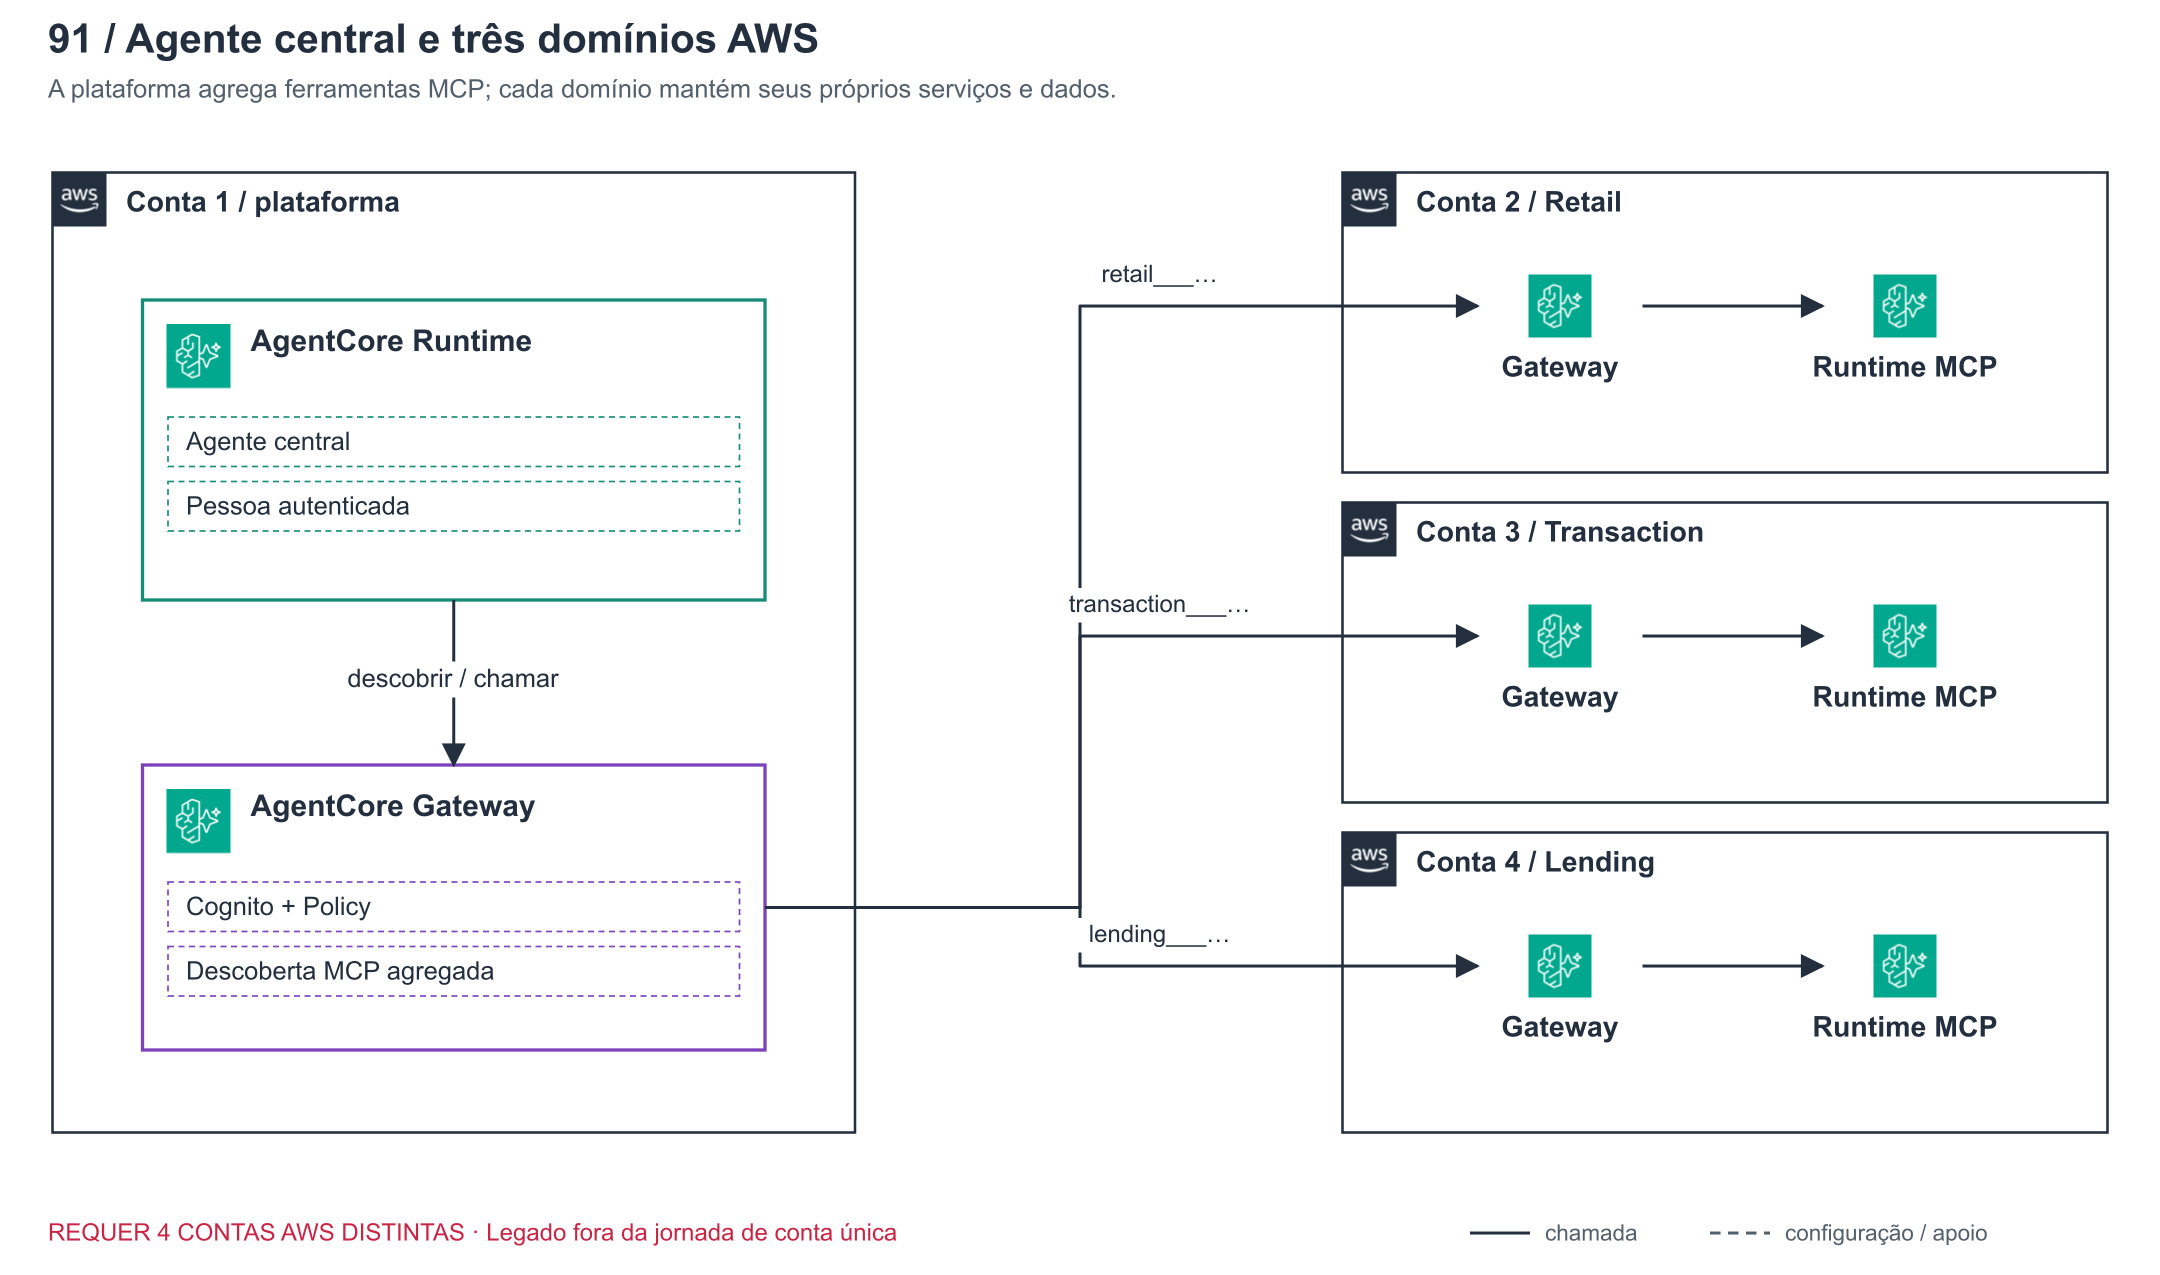

**Como ler o desenho:** O hub reúne contratos MCP, mas os serviços e suas permissões continuam em contas separadas. Siga cada ramificação até a conta correspondente; centralizar descoberta não move os dados para a plataforma.

[Abrir PNG](../docs/diagramas/aulas/91.png) · [Abrir SVG](../docs/diagramas/aulas/91.svg)

## O que você vai aprender

**Pergunta da aula:** Como um ponto central de descoberta alcança capacidades distribuídas em três domínios?

1. Relacionar os prefixos MCP aos domínios.
2. Seguir a chamada do agente central até o Runtime do domínio solicitado.

**Estudo do legado — quatro contas AWS distintas.** Esta aula ainda depende da implantação anterior e não foi validada na jornada SDK atual. Não execute este notebook na conta única do Workshop Studio.

**Antes de começar:** Legado: quatro contas e os targets federados previamente implantados.

**O que esta aula cria ou remove:** Nenhum recurso; inspeciona targets e chama os agentes do ambiente legado.

**O que reutiliza:** Plataforma central, Cognito e os três domínios preparados na arquitetura anterior.

## Serviços AWS e suas responsabilidades

| Serviço | O que ele faz | Papel nesta aula |
|---|---|---|
| **Amazon Bedrock AgentCore Gateway** | Expõe ferramentas por MCP, autentica chamadas e encaminha operações aos targets. O schema informa nome, argumentos e contrato de cada ferramenta. | Centraliza a descoberta e apresenta prefixos retail, transaction e lending. |
| **Amazon Bedrock AgentCore Runtime** | Hospeda código de agentes ou servidores MCP com sessão, endpoint e role de execução. A identidade que invoca o endpoint é distinta da identidade usada pelo código hospedado. | Executa o agente e as capacidades distribuídas. |
| **Amazon Bedrock AgentCore Policy** | Avalia regras Cedar sobre principal, ação, recurso e contexto de uma chamada. O engine associado ao Gateway em ENFORCE aplica suas decisões antes da ferramenta. | Aplica autorização no caminho federado. |
| **Amazon Cognito — User Pool** | Mantém usuários e aplicações e emite JWTs assinados após a autenticação. Issuer identifica o emissor, sub identifica a pessoa e aud identifica a aplicação destinatária. | Identifica a pessoa nas chamadas do cenário. |
| **AWS Identity and Access Management (IAM)** | Controla quais ações uma identidade pode executar em quais recursos. A trust policy define quem pode assumir uma role; a policy de permissões define seu acesso. | Delimita as permissões dos serviços entre contas. |

**Roteiro de execução:** leia a configuração e o código, execute a célula, aguarde o estado indicado e interprete a evidência antes de avançar. As seções **Validação** destacam chamadas e asserts já presentes na aula. Um erro inesperado não equivale a uma negativa autorizada esperada.

## Pré-requisito: 4 contas AWS distintas

**Esta aula não executa em uma conta única.** O fluxo mostrado envolve 4 contas (platform, retail-banking, transaction-banking, lending-wealth), mas o manifesto e o IaC atuais exigem as quatro contas preparadas: plataforma, Retail, Transaction e Lending. Sem elas, reserve a aula para demonstração do instrutor no ambiente completo ou retire-a da seleção de execução.

A jornada SDK atual de conta única inclui 00–09 e 15–16. Os recursos dessas aulas não preparam esta integração legada. Confira a [matriz de contas e execução](../docs/contas-e-elegibilidade.md).

Todos os serviços e agentes desta jornada são implantados na AWS.
O notebook é o roteiro e cliente das APIs; ferramentas, inferência,
políticas, fontes e memória executam nos serviços indicados.
Use o ambiente AWS descrito no [guia de implantação](../docs/deploy.md).
Configure os identificadores dos stacks antes de executar. Uma
dependência ausente bloqueia a aula antes das chamadas do exercício.
Antes de usar “Run All”, selecione as aulas compatíveis com as contas
preparadas. O bloco 10–14 exige quatro contas na implantação atual.

### Carregar a configuração e conferir as dependências

A configuração contém perfis/roles e IDs, nunca senhas ou tokens. O STS confirma a conta antes de consultar os stacks; o manifesto exige as dependências desta aula.

In [ ]:
import json
import os
import uuid
from pathlib import Path
from IPython.display import Code, display
import inspect
from santander_demo.aws_workshop.client import AWSWorkshop
from santander_demo.aws_workshop.config import load
from santander_demo.aws_workshop.manifest import require

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
CONFIG = Path(os.environ.get("WORKSHOP_CONFIG", ROOT / "config/aws.workshop.json"))
config = load(CONFIG)
dependencies = require(config, "11")
print({"lab": "11", "dependencies": list(dependencies), "region": config["region"]})

### Conectar ao ambiente implantado

Lemos os outputs exatos do CloudFormation. O cliente não cria infraestrutura e não substitui um serviço indisponível.

In [ ]:
lab = AWSWorkshop(CONFIG, domain="platform")
print(lab.preflight())

### Autenticar a pessoa no Cognito

O login usa USER_PASSWORD_AUTH para usuários sintéticos do workshop e SECRET_HASH para o cliente confidencial. Em uma aplicação de usuários finais, use authorization code com PKCE. O código abaixo mostra a chamada Cognito e a verificação de assinatura, emissor, audiência e token_use. Só imprimimos claims selecionadas.

In [ ]:
from santander_demo.aws_workshop.identity import login, verify
display(Code(inspect.getsource(login), language="python"))
display(Code(inspect.getsource(verify), language="python"))
token = lab.login("c", "supervisor")
claims = lab.claims(token)
print({key: claims[key] for key in ["iss", "sub", "aud", "token_use"]})

### Inspecionar os targets do hub

O Gateway da plataforma agrega os Gateways de Retail, Transaction e Lending. O schema está no IaC; não precisamos de um token humano durante a criação dos targets.

In [ ]:
display(Code((ROOT / "infra/workshop/templates/federation-bindings.json").read_text(), language="json"))
names = [x["name"] for x in await lab.tools(token)]
for prefix in ["retail___", "transaction___", "lending___"]:
    assert any(name.startswith(prefix) for name in names)
print(names)

### Fazer o agente consultar três contas

O notebook envia perguntas. Escolha de ferramenta, inferência Bedrock e chamadas MCP executam no Runtime da plataforma.

### Validação — execução nos domínios

A célula abaixo executa as verificações deste ponto. Compare sua saída com os critérios antes de continuar.

| Caso observado | Resultado esperado | O que comprova |
|---|---|---|
| Retail, Transaction e Lending | Resposta `execution: AWS_AGENTCORE_RUNTIME` para cada domínio | O helper recebeu respostas de execução Runtime. |

In [ ]:
results = {}
for domain in ["retail-banking", "transaction-banking", "lending-wealth"]:
    result = await lab.invoke_agent(token, "Consulte o risco sintético de C001.", domain=domain)
    assert result["execution"] == "AWS_AGENTCORE_RUNTIME"
    results[domain] = result
print(json.dumps(results, indent=2, ensure_ascii=False))

### Leitura do resultado — execução nos domínios

Compare domínio, IDs de requisição e conteúdo de cada resposta. A marca de execução é o assert visível desta célula; ela sozinha não constitui auditoria completa de todas as fronteiras.

**Relação com os exemplos oficiais:** o serviço Gateway centraliza a descoberta MCP. Aqui preservamos a pessoa com JWT Cognito e políticas independentes. O fluxo M2M de aplicação é demonstrado separadamente no laboratório 09; não equivale a OBO.

### Evidências e encerramento

Registre IDs de requisição e decisões, sem tokens ou senhas. Os recursos são compartilhados entre aulas: a remoção pertence ao pipeline de limpeza do projeto e deve respeitar essa dependência.

## Análise dos resultados

A arquitetura separa descoberta central de execução distribuída e torna visível o roteamento por domínio.

**Evidência e alcance:** Esta aula continua **pendente de conversão e teste no ambiente atual**. Os resultados acima são critérios esperados do código legado, não uma nova evidência de execução.

**Limites da demonstração:** Os resultados desta versão não foram revalidados na conta efêmera atual. O cenário depende de quatro contas e do fluxo legado de implantação.

**Para discutir:** Qual parte é centralizada pelo hub, e quais decisões continuam pertencendo aos domínios?

**Registro da aula:** anote conta/região, run_id quando disponível, casos permitidos/negados e IDs de requisição. Preserve a mensagem de uma falha inesperada; não publique tokens, senhas ou credenciais nas saídas. Os notebooks do repositório são distribuídos sem outputs.